# Experiment 5: Reinforcement learning (tabular Q-learning)
A 5 x 7 grid world with walls, a goal (+10), a pit (-10) and a step cost (-0.1).

In [1]:
import json
import numpy as np
import matplotlib.pyplot as plt

H, W = 5, 7
WALLS = {(1, 2), (2, 2), (3, 2), (1, 4), (2, 4)}
GOAL, PIT, START = (0, W - 1), (2, W - 1), (H - 1, 0)
A = [(-1, 0), (1, 0), (0, -1), (0, 1)]          # up, down, left, right
ARROW = ["↑", "↓", "←", "→"]
ALPHA, GAMMA, EPISODES, STEP_CAP, SEED = 0.5, 0.95, 600, 120, 0
EPSILONS = (0.01, 0.10, 0.20, 0.50)

def step(s, a):
    r, c = s; dr, dc = A[a]; nr, nc = r + dr, c + dc
    if not (0 <= nr < H and 0 <= nc < W) or (nr, nc) in WALLS:
        nr, nc = r, c                            # bumping a wall wastes the step
    ns = (nr, nc)
    if ns == GOAL: return ns, +10.0, True
    if ns == PIT:  return ns, -10.0, True
    return ns, -0.1, False

## Q-learning

In [2]:
def train(eps, episodes=EPISODES, alpha=ALPHA, gamma=GAMMA, seed=SEED):
    rng = np.random.default_rng(seed)
    Q = np.zeros((H, W, 4))
    curve = []
    for _ in range(episodes):
        s, total = START, 0.0
        for _ in range(STEP_CAP):
            a = rng.integers(4) if rng.random() < eps else int(np.argmax(Q[s]))
            ns, r, done = step(s, a)
            total += r
            target = r + gamma*np.max(Q[ns])*(not done)     # no future after a terminal state
            Q[s][a] += alpha*(target - Q[s][a])             # TD update
            s = ns
            if done: break
        curve.append(total)
    return Q, np.array(curve)

## Reference: optimal Q* by value iteration (same MDP), and a greedy roll-out

In [3]:
def value_iteration(gamma=GAMMA, tol=1e-10):
    Q = np.zeros((H, W, 4))
    while True:
        Qn = np.zeros_like(Q)
        for r in range(H):
            for c in range(W):
                if (r, c) in WALLS or (r, c) in (GOAL, PIT): continue
                for a in range(4):
                    ns, rew, done = step((r, c), a)
                    Qn[r, c, a] = rew + gamma*np.max(Q[ns])*(not done)
        if np.abs(Qn - Q).max() < tol: return Qn
        Q = Qn

def rollout(Q):
    s, total, path = START, 0.0, [START]
    for _ in range(STEP_CAP):
        s, r, done = step(s, int(np.argmax(Q[s])))
        total += r; path.append(s)
        if done: break
    return total, path

Qstar = value_iteration()
opt_return, opt_path = rollout(Qstar)
FREE = [(r, c) for r in range(H) for c in range(W) if (r, c) not in WALLS and (r, c) not in (GOAL, PIT)]

def policy_agreement(Q):
    """States whose greedy action is one of the optimal actions (ties allowed)."""
    good = sum(Qstar[s][int(np.argmax(Q[s]))] >= Qstar[s].max() - 1e-6 for s in FREE)
    return int(good)

print(f"optimal return from start = {opt_return:.2f} in {len(opt_path)-1} steps")

optimal return from start = 9.10 in 10 steps


## Effect of the exploration rate

{'eps': 0.01, 'mean_last100': 9.08, 'greedy_return': 9.1, 'greedy_steps': 10, 'greedy_reaches_goal': True, 'states_optimal': 26, 'first_positive_episode': 3}


{'eps': 0.1, 'mean_last100': 8.997000000000002, 'greedy_return': 9.1, 'greedy_steps': 10, 'greedy_reaches_goal': True, 'states_optimal': 26, 'first_positive_episode': 1}


{'eps': 0.2, 'mean_last100': 8.857999999999999, 'greedy_return': 9.1, 'greedy_steps': 10, 'greedy_reaches_goal': True, 'states_optimal': 28, 'first_positive_episode': 3}


{'eps': 0.5, 'mean_last100': 7.442, 'greedy_return': 9.1, 'greedy_steps': 10, 'greedy_reaches_goal': True, 'states_optimal': 28, 'first_positive_episode': 2}


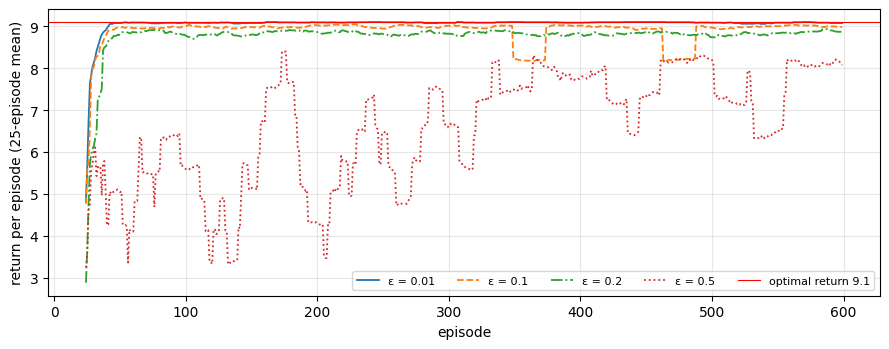

In [4]:
def smooth(v, k=25):
    return np.convolve(v, np.ones(k)/k, mode="valid")

R = {"grid": [H, W], "walls": sorted(WALLS), "goal": GOAL, "pit": PIT, "start": START,
     "alpha": ALPHA, "gamma": GAMMA, "episodes": EPISODES, "step_cap": STEP_CAP, "seed": SEED,
     "optimal_return": opt_return, "optimal_steps": len(opt_path) - 1, "free_states": len(FREE), "runs": []}
Qs = {}
fig, ax = plt.subplots(figsize=(9, 3.6))
for eps, st in zip(EPSILONS, ("-", "--", "-.", ":")):
    Q, curve = train(eps)
    Qs[eps] = Q
    g_ret, g_path = rollout(Q)
    first_goal = int(np.argmax(curve > 0))          # first episode with a positive return
    run = dict(eps=eps, mean_last100=float(curve[-100:].mean()), greedy_return=g_ret,
               greedy_steps=len(g_path) - 1, greedy_reaches_goal=g_path[-1] == GOAL,
               states_optimal=policy_agreement(Q), first_positive_episode=first_goal)
    R["runs"].append(run); print(run)
    ax.plot(np.arange(24, EPISODES), smooth(curve), st, lw=1.3, label=f"ε = {eps}")
ax.axhline(opt_return, color="r", lw=0.8, label=f"optimal return {opt_return:.1f}")
ax.set(xlabel="episode", ylabel="return per episode (25-episode mean)")
ax.legend(fontsize=8, ncol=5, loc="lower right"); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig("figs/fig5_1_learning_curves.png", dpi=150); plt.show()

## Greedy policy after training at ε = 0.20

→ → → → → → G
→ ↑ # ↑ # ↑ ↑
↑ ↑ # ↑ # ↑ P
↑ ↑ # ↑ → ↑ ←
↑ → → ↑ → ↑ ←


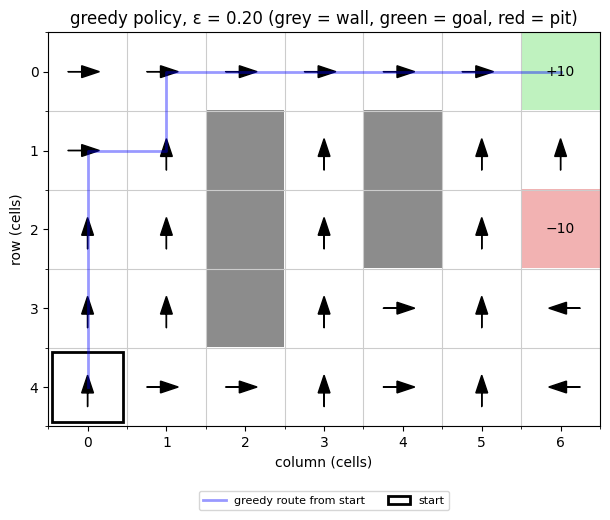

In [5]:
Q = Qs[0.20]
policy = np.argmax(Q, axis=2)
_, path = rollout(Q)
grid_txt = []
for r in range(H):
    row = []
    for c in range(W):
        s = (r, c)
        row.append("#" if s in WALLS else "G" if s == GOAL else "P" if s == PIT else ARROW[policy[s]])
    grid_txt.append(" ".join(row))
print("\n".join(grid_txt))
R["policy_grid_eps0.20"] = grid_txt

fig, ax = plt.subplots(figsize=(6.2, 5))
img = np.ones((H, W, 3))
for s in WALLS: img[s] = (0.55, 0.55, 0.55)
img[GOAL] = (0.75, 0.95, 0.75); img[PIT] = (0.95, 0.7, 0.7)
ax.imshow(img, extent=(-0.5, W - 0.5, H - 0.5, -0.5))
for r, c in FREE:
    dr, dc = A[policy[r, c]]
    ax.arrow(c - 0.25*dc, r - 0.25*dr, 0.4*dc, 0.4*dr, head_width=0.15, color="k", length_includes_head=True)
ax.plot([c for _, c in path], [r for r, _ in path], color="b", lw=2, alpha=0.4, label="greedy route from start")
ax.add_patch(plt.Rectangle((START[1] - 0.45, START[0] - 0.45), 0.9, 0.9, fill=False, lw=2, label="start"))
ax.text(GOAL[1], GOAL[0], "+10", ha="center", va="center"); ax.text(PIT[1], PIT[0], "−10", ha="center", va="center")
ax.set(xticks=range(W), yticks=range(H), xlabel="column (cells)", ylabel="row (cells)",
       title="greedy policy, ε = 0.20 (grey = wall, green = goal, red = pit)")
ax.set_xticks(np.arange(-0.5, W), minor=True); ax.set_yticks(np.arange(-0.5, H), minor=True)
ax.grid(which="minor", color="0.8"); ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)
fig.tight_layout(); fig.savefig("figs/fig5_2_policy.png", dpi=150); plt.show()

In [6]:
json.dump(R, open("results.json", "w"), indent=1, default=lambda o: o if not isinstance(o, np.generic) else o.item())